# Atlas DeePC Reacher: Stabilizing Offline Data, Multi-Target Test

This notebook tests the pragmatic hypothesis from our discussion:

```text
If the offline data already contains successful reaching/stabilizing behavior,
can atlas/subspace DeePC reuse that behavior to reach multiple target seeds?
```

This is **not** the fair Select-DPC IID-random-data experiment. Here the offline data is deliberately collected from stabilizing Reacher rollouts using the IK-PD behavior generator in `expert_pipeline_search.py`, with small exploration noise. The point is to test DeePC's ability to reuse successful behavior, not to claim the offline data is policy-free.


In [43]:
# =========================
# 0) Imports and paths
# =========================
from pathlib import Path
import json
import os

PROJECT_DIR = Path.cwd().resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_DIR / ".matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(PROJECT_DIR / ".cache"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)
Path(os.environ["XDG_CACHE_HOME"]).mkdir(exist_ok=True)

import importlib
import matplotlib.pyplot as plt
import numpy as np

import expert_pipeline_search as pipe
pipe = importlib.reload(pipe)

HANKEL_PATH = PROJECT_DIR / "stabilizing_offline_hankel.npy"
LABEL_PATH = PROJECT_DIR / "stabilizing_prediction_error_labels.npz"
SUBSPACE_PATH = PROJECT_DIR / "stabilizing_prediction_error_subspaces_rank90.npz"
SUMMARY_PATH = PROJECT_DIR / "stabilizing_multitarget_summary.json"
RESULT_DIR = PROJECT_DIR / "stabilizing_multitarget_results"
RESULT_DIR.mkdir(exist_ok=True)

print("Project:", PROJECT_DIR)
print("Hankel path:", HANKEL_PATH)
print("Result dir:", RESULT_DIR)


Project: /Users/kumiko/Projects/atlas_deepc_reacher
Hankel path: /Users/kumiko/Projects/atlas_deepc_reacher/stabilizing_offline_hankel.npy
Result dir: /Users/kumiko/Projects/atlas_deepc_reacher/stabilizing_multitarget_results


In [44]:
# =========================
# 1) DeePC window/horizon settings
# =========================
# The tuned seed-42 stabilizing-offline case uses the same length-12 Hankel
# windows as before, but with a short measured past and longer planned future.
# The 6/6 split is a noticeably different controller and does not reproduce the
# successful seed-42 trajectory.
CONTROL_T_INI = 2
CONTROL_T_F = 10
pipe.T_INI = CONTROL_T_INI
pipe.T_F = CONTROL_T_F
pipe.L = CONTROL_T_INI + CONTROL_T_F

print({"T_ini": pipe.T_INI, "T_f": pipe.T_F, "L": pipe.L})


{'T_ini': 2, 'T_f': 10, 'L': 12}


In [45]:
# =========================
# 2) Collect stabilizing offline data
# =========================
# This is the key difference from the fair IID notebook.
# The rollouts use the IK-PD behavior generator plus small noise, so the offline
# Hankel library contains successful approach and local regulation behavior.
FORCE_RECOLLECT = False
EXPERT_SEED = 123
EXPERT_EPISODES = 140
EXPERT_EPISODE_LEN = 180
EXPERT_U_LIMIT = 0.5
EXPERT_NOISE_STD = 0.035

if FORCE_RECOLLECT or not HANKEL_PATH.exists():
    old_data_path = pipe.DATA_PATH
    pipe.DATA_PATH = HANKEL_PATH
    H = pipe.collect_expert_hankel(
        seed=EXPERT_SEED,
        episodes=EXPERT_EPISODES,
        episode_len=EXPERT_EPISODE_LEN,
        limit=EXPERT_U_LIMIT,
        noise_std=EXPERT_NOISE_STD,
    )
    pipe.DATA_PATH = old_data_path
else:
    H = np.load(HANKEL_PATH)

print("H shape:", H.shape)
print("input range:", H[:pipe.M * pipe.L].min(), H[:pipe.M * pipe.L].max())


H shape: (144, 23660)
input range: -0.5 0.5


In [46]:
# =========================
# 3) Learn prediction-error atlas
# =========================
# Same atlas idea: KMeans initialization, then refinement by local prediction error.
# Important: prediction-error labels depend on the DeePC split because W/Y use
# T_INI and T_F. If the saved labels were made under a different split, relearn.
FORCE_RELEARN_ATLAS = False

labels_need_relearn = FORCE_RELEARN_ATLAS or not LABEL_PATH.exists()
if LABEL_PATH.exists() and not labels_need_relearn:
    label_data = np.load(LABEL_PATH)
    label_t_ini = int(label_data["t_ini"]) if "t_ini" in label_data.files else None
    label_t_f = int(label_data["t_f"]) if "t_f" in label_data.files else None
    if label_t_ini != pipe.T_INI or label_t_f != pipe.T_F:
        print(
            "Saved labels use a different DeePC split:",
            {"saved_t_ini": label_t_ini, "saved_t_f": label_t_f},
            "current:",
            {"t_ini": pipe.T_INI, "t_f": pipe.T_F},
        )
        labels_need_relearn = True

if labels_need_relearn:
    labels = pipe.learn_prediction_error_atlas(H, seed=7, label_path=LABEL_PATH)
else:
    labels = np.load(LABEL_PATH)["labels"]

print("K:", pipe.K)
print("cluster sizes:", np.bincount(labels, minlength=pipe.K).tolist())


Saved labels use a different DeePC split: {'saved_t_ini': None, 'saved_t_f': None} current: {'t_ini': 2, 't_f': 10}
K: 8
cluster sizes: [4329, 2618, 1829, 4289, 1779, 2475, 5174, 1167]


In [47]:
# =========================
# 4) Build chart subspaces
# =========================
SUBSPACE_RANK = 90
SUBSPACE_ENERGY = None
subspace_bases = pipe.compute_bases(H, labels, rank=SUBSPACE_RANK, energy=SUBSPACE_ENERGY)
subspace_ranks = [0 if basis is None else basis.shape[1] for basis in subspace_bases]

np.savez(
    SUBSPACE_PATH,
    ranks=np.asarray(subspace_ranks, dtype=int),
    labels=labels,
    rank=np.array(SUBSPACE_RANK),
    t_ini=np.array(pipe.T_INI),
    t_f=np.array(pipe.T_F),
)

print("subspace rank cap:", SUBSPACE_RANK)
print("subspace ranks by chart:", subspace_ranks)


subspace rank cap: 90
subspace ranks by chart: [90, 90, 90, 90, 90, 90, 90, 90]


In [ ]:
# =========================
# 5) Seed-1 bounded-subspace atlas DeePC diagnostic
# =========================
# This cell keeps online chart selection enabled and uses the local SVD subspace
# basis for the selected prediction-error chart. It is the repaired seed-1
# diagnostic configuration: coefficient bounds prevent the zero-input fantasy,
# and the terminal weight/IK reference make the controller actually drive toward
# the target. It is still not a verified seed-1 success; inspect the tail metrics
# and tracking plot before claiming stabilization.
EVAL_SEEDS = [1]
FIXED_CHART = None
MAKE_VIDEOS = False

BASE_VARIANT = dict(
    name="stabilizing_offline_subspace_online_bounded",
    mode="subspace",
    rank=SUBSPACE_RANK,
    energy=SUBSPACE_ENERGY,
    max_cols=500,
    try_top=1,
    u_limit=0.5,
    q_xy=500000.0,
    q_dq=1000.0,
    q_joint=1000.0,
    q_sum=0.0,
    q_terminal_xy=2000000.0,
    q_terminal_dq=1000.0,
    q_terminal_joint=0.0,
    q_terminal_sum=0.0,
    r=0.001,
    lam_g=0.05,
    lam_ini=100000.0,
    lam_du=3.0,
    solver="CLARABEL",
    steps=320,
    warmup_scale=0.0,
    chart_selection="best_relevance",
    relevance_past_weight=0.1,
    chart_switch_cost=0.08,
    coef_bound_scale=0.75,
    coef_bound_affine=False,
    selection_residual_weight=0.0,
    selection_g_weight=0.0,
    selection_past_weight=0.0,
    selection_zero_action_weight=0.0,
    selection_min_action_norm=0.0,
    selection_relevance_weight=0.0,
    fixed_chart=FIXED_CHART,
    use_ik_ref=True,
    ik_elbow="down",
)

summaries = []
for seed in EVAL_SEEDS:
    variant = pipe.Variant(**{**BASE_VARIANT, "name": f"stabilizing_offline_seed{seed}_bounded_subspace", "seed": seed})
    result_path = RESULT_DIR / f"seed{seed}_control_results.npz"
    video_path = RESULT_DIR / f"seed{seed}_control.mp4" if MAKE_VIDEOS else None
    print("RUN", variant)
    summary = pipe.run_atlas_deepc(H, labels, variant, save_path=result_path, video_path=video_path)
    data = np.load(result_path, allow_pickle=True)
    dist = np.asarray(data["distance"], dtype=float)
    summary["tail50_mean"] = float(dist[-50:].mean())
    summary["tail50_max"] = float(dist[-50:].max())
    summary["best_step"] = int(dist.argmin())
    summary["result_path"] = str(result_path)
    summary["video_path"] = str(video_path) if video_path is not None else None
    summaries.append(summary)
    print(" ->", summary)

SUMMARY_PATH.write_text(json.dumps(summaries, indent=2))
summaries


RUN Variant(name='stabilizing_offline_seed1_chartNone', mode='subspace', rank=90, energy=None, max_cols=500, try_top=8, u_limit=0.5, q_xy=2000.0, q_dq=10.0, q_joint=0.0, q_sum=0.0, r=1, lam_g=1, lam_ini=100000.0, lam_du=5.0, solver='CLARABEL', steps=320, warmup_scale=0.0, seed=1, chart_selection='best_predicted', selection_residual_weight=0.0, selection_g_weight=0.0, fixed_chart=None, use_ik_ref=False, ik_elbow='down')
 -> {'name': 'stabilizing_offline_seed1_chartNone', 'mode': 'subspace', 'rank': 90, 'energy': None, 'max_cols': 500, 'try_top': 8, 'u_limit': 0.5, 'q_xy': 2000.0, 'q_dq': 10.0, 'q_joint': 0.0, 'q_sum': 0.0, 'r': 1, 'lam_g': 1, 'lam_ini': 100000.0, 'lam_du': 5.0, 'solver': 'CLARABEL', 'steps': 320, 'warmup_scale': 0.0, 'seed': 1, 'chart_selection': 'best_predicted', 'selection_residual_weight': 0.0, 'selection_g_weight': 0.0, 'fixed_chart': None, 'use_ik_ref': False, 'ik_elbow': 'down', 'n_steps': 320, 'first': 0.28774715939245066, 'min': 0.28774715939245066, 'last': 0.28

[{'name': 'stabilizing_offline_seed1_chartNone',
  'mode': 'subspace',
  'rank': 90,
  'energy': None,
  'max_cols': 500,
  'try_top': 8,
  'u_limit': 0.5,
  'q_xy': 2000.0,
  'q_dq': 10.0,
  'q_joint': 0.0,
  'q_sum': 0.0,
  'r': 1,
  'lam_g': 1,
  'lam_ini': 100000.0,
  'lam_du': 5.0,
  'solver': 'CLARABEL',
  'steps': 320,
  'warmup_scale': 0.0,
  'seed': 1,
  'chart_selection': 'best_predicted',
  'selection_residual_weight': 0.0,
  'selection_g_weight': 0.0,
  'fixed_chart': None,
  'use_ik_ref': False,
  'ik_elbow': 'down',
  'n_steps': 320,
  'first': 0.28774715939245066,
  'min': 0.28774715939245066,
  'last': 0.2888963895188613,
  'mean_last_30': 0.28885339485460976,
  'max_last_30': 0.2888963895188613,
  'mean': 0.28835865318212556,
  'success': False,
  'unique_charts': [0],
  'statuses': {'optimal': 320},
  'tail50_mean': 0.2888230822466258,
  'tail50_max': 0.2888963895188613,
  'result_path': '/Users/kumiko/Projects/atlas_deepc_reacher/stabilizing_multitarget_results/seed1

success count: 0 / 1
seed=  1 success=False last=0.2889 mean30=0.2889 max30=0.2889 tail50=0.2888/0.2889 charts=[0]


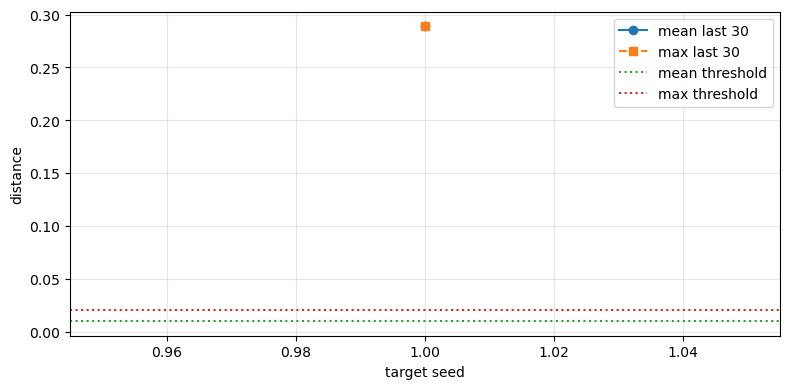

In [49]:
# =========================
# 6) Summarize multi-target results
# =========================
if SUMMARY_PATH.exists():
    summaries = json.loads(SUMMARY_PATH.read_text())

success_flags = [row["success"] for row in summaries]
print("success count:", sum(success_flags), "/", len(success_flags))
for row in summaries:
    print(
        f"seed={row['seed']:>3} success={row['success']} "
        f"last={row['last']:.4f} mean30={row['mean_last_30']:.4f} max30={row['max_last_30']:.4f} "
        f"tail50={row['tail50_mean']:.4f}/{row['tail50_max']:.4f} charts={row['unique_charts']}"
    )

fig, ax = plt.subplots(figsize=(8, 4))
seeds = [row["seed"] for row in summaries]
mean30 = [row["mean_last_30"] for row in summaries]
max30 = [row["max_last_30"] for row in summaries]
ax.plot(seeds, mean30, "o-", label="mean last 30")
ax.plot(seeds, max30, "s--", label="max last 30")
ax.axhline(0.01, color="tab:green", linestyle=":", label="mean threshold")
ax.axhline(0.02, color="tab:red", linestyle=":", label="max threshold")
ax.set_xlabel("target seed")
ax.set_ylabel("distance")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


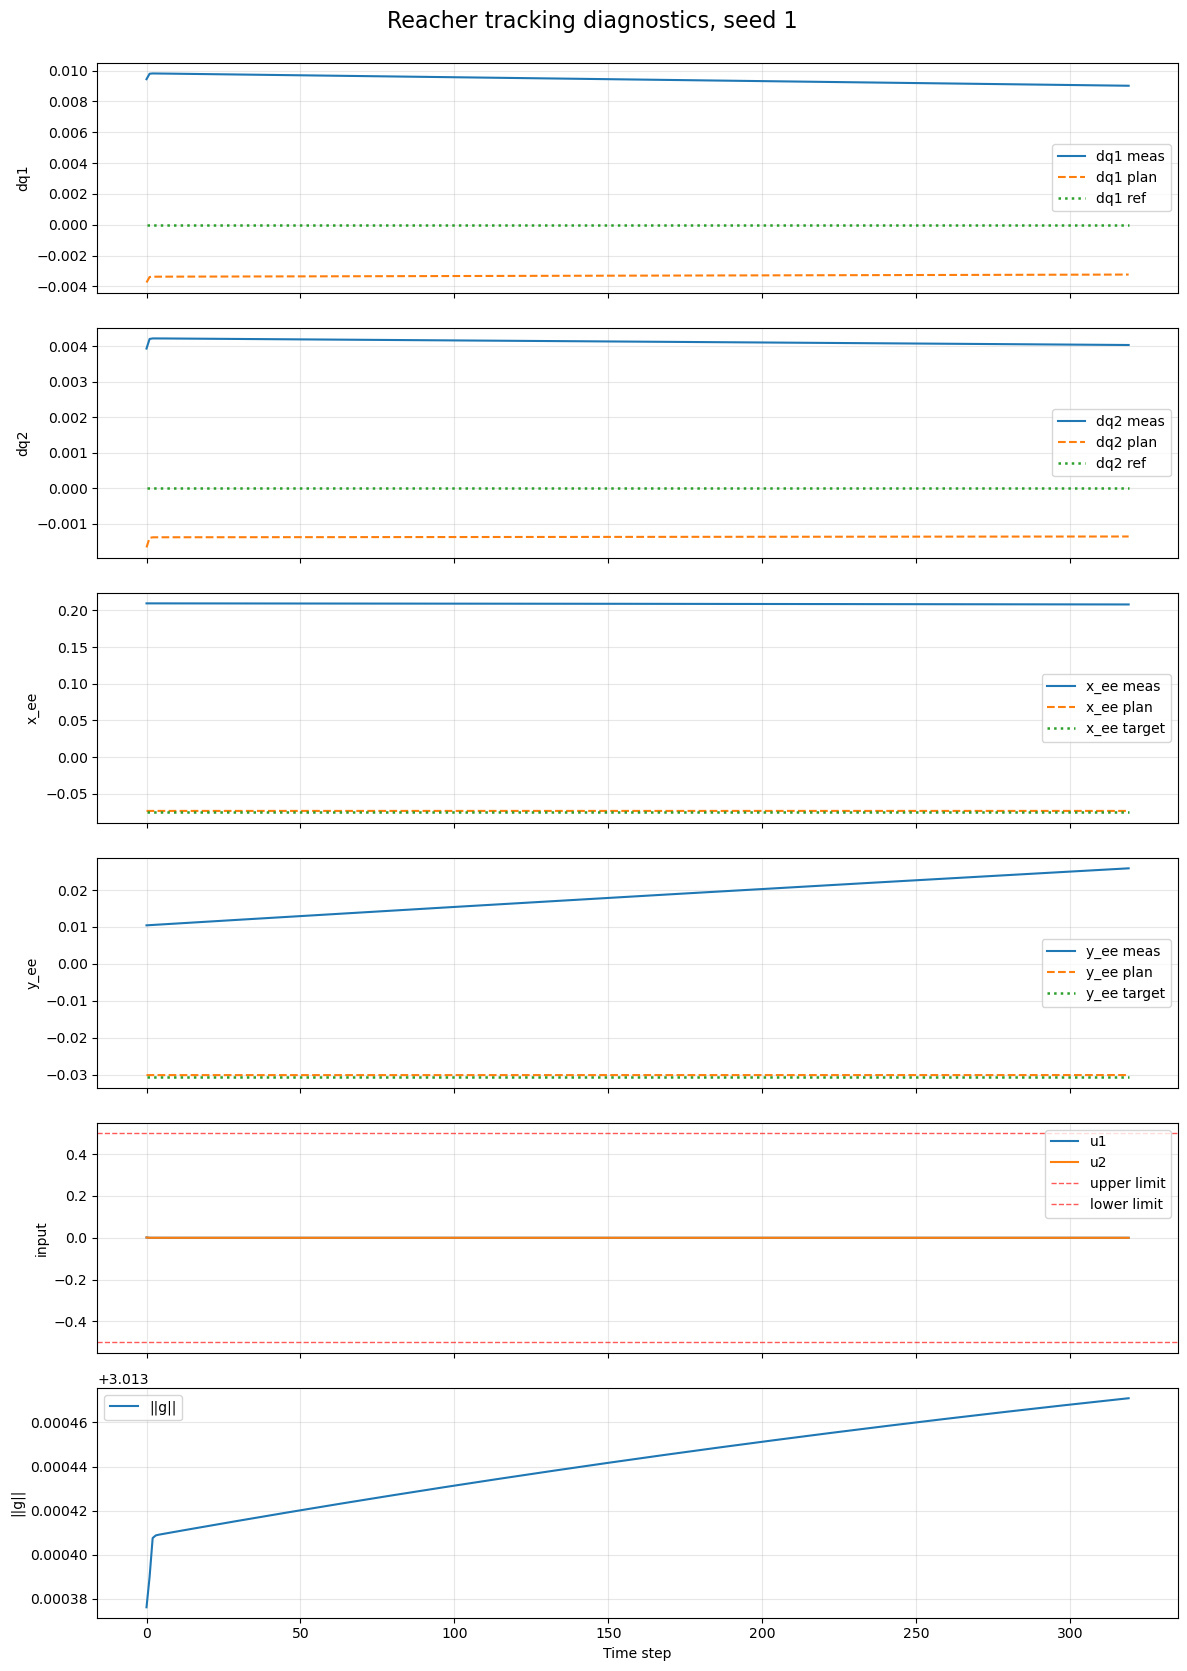

first: 0.28774715939245066
min: 0.28774715939245066
last: 0.2888963895188613
mean last 30: 0.28885339485460976
max last 30: 0.2888963895188613
tail50 mean/max: 0.2888230822466258 0.2888963895188613
unique charts: [0]


In [50]:
# =========================
# 7) Tracking diagnostics for one target seed
# =========================
PLOT_SEED = 1
result_path = RESULT_DIR / f"seed{PLOT_SEED}_control_results.npz"
data = np.load(result_path, allow_pickle=True)
y = np.asarray(data["y"], dtype=float)
ref = np.asarray(data["ref"], dtype=float)
u = np.asarray(data["u"], dtype=float)
y_plan = np.asarray(data["pred"], dtype=float) if "pred" in data.files else np.full_like(y, np.nan)
g_norm = np.asarray(data["g_norm"], dtype=float) if "g_norm" in data.files else np.full(y.shape[0], np.nan)
dist = np.asarray(data["distance"], dtype=float)

horizon = min(y.shape[0], ref.shape[0], u.shape[0], y_plan.shape[0], g_norm.shape[0], dist.shape[0])
t = np.arange(horizon)
y = y[:horizon]
ref = ref[:horizon]
u = u[:horizon]
y_plan = y_plan[:horizon]
g_norm = g_norm[:horizon]

fig, axes = plt.subplots(6, 1, figsize=(12, 17), sharex=True)
fig.suptitle(f"Reacher tracking diagnostics, seed {PLOT_SEED}", fontsize=16)
plot_specs = [
    (4, "dq1", "dq1 meas", "dq1 plan", "dq1 ref"),
    (5, "dq2", "dq2 meas", "dq2 plan", "dq2 ref"),
    (6, "x_ee", "x_ee meas", "x_ee plan", "x_ee target"),
    (7, "y_ee", "y_ee meas", "y_ee plan", "y_ee target"),
]
for ax, (channel, ylabel, meas_label, plan_label, ref_label) in zip(axes[:4], plot_specs):
    ax.plot(t, y[:, channel], label=meas_label)
    ax.plot(t, y_plan[:, channel], "--", label=plan_label)
    ax.plot(t, ref[:, channel], ":", linewidth=1.8, label=ref_label)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")

axes[4].plot(t, u[:, 0], label="u1")
axes[4].plot(t, u[:, 1], label="u2")
axes[4].axhline(BASE_VARIANT["u_limit"], color="red", linestyle="--", linewidth=1.0, alpha=0.65, label="upper limit")
axes[4].axhline(-BASE_VARIANT["u_limit"], color="red", linestyle="--", linewidth=1.0, alpha=0.65, label="lower limit")
axes[4].set_ylabel("input")
axes[4].grid(True, alpha=0.3)
axes[4].legend(loc="best")

axes[5].plot(t, g_norm, label="||g||")
axes[5].set_ylabel("||g||")
axes[5].set_xlabel("Time step")
axes[5].grid(True, alpha=0.3)
axes[5].legend(loc="best")

fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

print("first:", dist[0])
print("min:", dist.min())
print("last:", dist[-1])
print("mean last 30:", dist[-30:].mean())
print("max last 30:", dist[-30:].max())
print("tail50 mean/max:", dist[-50:].mean(), dist[-50:].max())
print("unique charts:", np.unique(data["chart"]).astype(int).tolist())


## Interpretation

This notebook intentionally uses stabilizing behavior in the offline library. If this succeeds across several target seeds, the result should be framed honestly:

```text
Atlas/subspace DeePC can efficiently reuse successful local reaching behavior
stored in the offline Hankel library.
```

That is different from the fair IID-data claim. It is still useful: it tests whether atlas/subspace compression lets DeePC generalize useful behavior across multiple nearby Reacher targets, and it makes the behavior-reuse mechanism explicit.
